#**Прогнозирование риска для материнского здоровья**

## Постановка задачи
В рамках тестового задания на производственную практику требуется
разработать модель машинного обучения для прогнозирования уровня
риска при беременности на основе физиологических показателей пациентки.

**Тип задачи:** Многоклассовая классификация (3 класса).\
**Источник данных:** Maternal Health Risk Data Set ([Kaggle](https://www.kaggle.com/datasets/csafrit2/maternal-health-risk-data))([Яндекс диск](https://disk.yandex.ru/i/iiyITm87PUzqZA)).

## Целевая переменная
`RiskLevel` ∈ {`low risk`, `mid risk`, `high risk`} —
оценка степени риска для матери и плода.

## Входные признаки
**Клинические показатели**: возраст, систолическое и диастолическое
артериальное давление, уровень глюкозы в крови, температура тела в градусах Фаренгейта,
частота сердечных сокращений.

## Критерии качества
- **Основная метрика:** F1-macro (устойчива к дисбалансу классов).
- **Дополнительные:** balanced accuracy, recall по `high risk`.
- **Обязательно:** матрица ошибок на тренировочной и тестовой выборках.

## Этапы работы
1. EDA: распределения, корреляции, баланс классов.
2. Препроцессинг: очистка, кодирование, масштабирование.
3. Разбиение: стратифицированный train/test split.
4. Моделирование: линейные и ансамблевые модели.
5. Оценка: метрики, матрицы ошибок, анализ переобучения.
6. Выводы: выбор финальной модели, интерпретация, ограничения.

**Изначально импортируем необходимые библиотеки:**

In [140]:
!pip install optuna catboost -q

In [141]:
import numpy as np
import pandas as pd
import requests
import io
import matplotlib.pyplot as plt
import seaborn as sns
import math
from urllib.parse import urlencode

import optuna
from optuna.samplers import TPESampler
from optuna.visualization.matplotlib import (
    plot_optimization_history,
    plot_param_importances,
)
from sklearn.model_selection import (train_test_split,
                                     StratifiedKFold,
                                     cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier,
                              StackingClassifier)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix,
                             make_scorer)

optuna.logging.set_verbosity(optuna.logging.WARNING) # Отключим логирование служеюных команд Optuna

## Загрузка данных

Датасет размещён на [Яндекс.Диске](https://disk.yandex.ru/i/iiyITm87PUzqZA).
Загрузим его в среду Google Colab для дальнейшего анализа и обучения моделей.

In [142]:
dataset_url = 'https://disk.yandex.ru/i/iiyITm87PUzqZA'
base_url = 'https://cloud-api.yandex.net/v1/disk/public/resources/download?'
url = base_url + urlencode(dict(public_key=dataset_url))
download_url = requests.get(url).json()['href']

response = requests.get(download_url)
response.raise_for_status()

df = pd.read_excel(io.BytesIO(response.content))
print(df.head())

/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


   Age  SystolicBP  DiastolicBP    BS  BodyTemp  HeartRate  RiskLevel
0   25         130           80  15.0      98.0         86  high risk
1   35         140           90  13.0      98.0         70  high risk
2   29          90           70   8.0     100.0         80  high risk
3   30         140           85   7.0      98.0         70  high risk
4   35         120           60   6.1      98.0         76   low risk


## Описание датасета

Данные успешно загружены с Яндекс.Диска. Датасет содержит следующие признаки:

| Признак | Описание |
|---|---|
| **Age** | Возраст женщины во время беременности (в годах). |
| **SystolicBP** | Верхний показатель артериального давления (мм рт. ст.). |
| **DiastolicBP** | Нижний показатель артериального давления (мм рт. ст.). |
| **BS** | Уровень глюкозы в крови в молярной концентрации (ммоль/л). |
| **BodyTemp** | Температура тела (°F). |
| **HeartRate** | Частота сердечных сокращений в покое (уд/мин). |
| **RiskLevel** | Целевая переменная: прогнозируемый уровень риска во время беременности. |

**Проверим основную информацию по датасету:**

In [143]:
print(f'Количество строк в датасете: {df.shape[0]}\nКоличество столбцов в датасете: {df.shape[1]}\n')
print(f'Информация по датасету:')
print(df.info())
print(f'\nПроверка столбцов на пропуски:')
print(df.isna().sum())
print(f'\nКоличество наблюдений в каждой категории риска:')
print(df['RiskLevel'].value_counts())

Количество строк в датасете: 1014
Количество столбцов в датасете: 7

Информация по датасету:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   object 
dtypes: float64(2), int64(4), object(1)
memory usage: 55.6+ KB
None

Проверка столбцов на пропуски:
Age            0
SystolicBP     0
DiastolicBP    0
BS             0
BodyTemp       0
HeartRate      0
RiskLevel      0
dtype: int64

Количество наблюдений в каждой категории риска:
RiskLevel
low risk     406
mid risk     336
high risk    272
Name: count, dtype: int64


### Первичные выводы по датасету

1. **Размер датасета:** 1014 наблюдений и 7 признаков — компактный набор данных,
   что накладывает ограничения на сложность моделей и требует аккуратной
   кросс-валидации.

2. **Пропуски отсутствуют:** все 7 столбцов заполнены полностью,
   предобработка по заполнению пропусков не требуется.

3. **Типы данных корректны:**
   - 4 целочисленных признака: `Age`, `SystolicBP`, `DiastolicBP`, `HeartRate`;
   - 2 вещественных: `BS`, `BodyTemp`;
   - 1 категориальный: `RiskLevel` (целевая переменная, требует кодирования).

4. **Целевая переменная — три класса с умеренным дисбалансом:**
   - `low risk` — 406 (40.0%);
   - `mid risk` — 336 (33.1%);
   - `high risk` — 272 (26.8%).

5. **Малый объём данных:** ~1000 строк — риск переобучения для ансамблевых
   моделей. Целесообразно ограничивать глубину деревьев и использовать
   кросс-валидацию для оценки стабильности.

**Таким образом, для данного датасета можно сразу сделать следующие предложения:**
- использовать **стратифицированное** разбиение на train/test;
- выбрать **F1-macro** или **balanced accuracy** в качестве основной метрики
  (обычная accuracy будет смещена в сторону `low risk`);
- рассмотреть `class_weight='balanced'` для линейных моделей.

### Проверим наличие дубликатов и при необходимости удалим их, чтобы избежать утечки данных между train и test.

In [144]:
print("Дубликатов:", df.duplicated().sum())

print(f'\nПримеры дубликатов из датасета:')
print(df[df.duplicated(keep=False)].sort_values(by=list(df.columns)).head(14))

Дубликатов: 562

Примеры дубликатов из датасета:
      Age  SystolicBP  DiastolicBP    BS  BodyTemp  HeartRate  RiskLevel
670    10         100           50   6.0      99.0         70   mid risk
849    10         100           50   6.0      99.0         70   mid risk
552    12          90           60   7.5     102.0         60   low risk
940    12          90           60   7.5     102.0         60   low risk
543    12          90           60   7.5     102.0         66   low risk
934    12          90           60   7.5     102.0         66   low risk
588    12          90           60   7.5     102.0         66   mid risk
827    12          90           60   7.5     102.0         66   mid risk
171    12          90           60   7.9     102.0         66  high risk
963    12          90           60   7.9     102.0         66  high risk
267    12          90           60   8.0     102.0         66  high risk
996    12          90           60   8.0     102.0         66  high risk
27

Дубликатов оказалось больше половины датасета. Удалим их и проверим
итоговый размер выборки:

In [145]:
df = df.drop_duplicates().reset_index(drop=True)
print(f'Количество строк в датасете: {df.shape[0]}\nКоличество столбцов в датасете: {df.shape[1]}\n')
print(f'Информация по датасету:')
print(df.info())
print(f'\nКоличество наблюдений в каждой категории риска:')
print(df['RiskLevel'].value_counts())

Количество строк в датасете: 452
Количество столбцов в датасете: 7

Информация по датасету:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 452 entries, 0 to 451
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          452 non-null    int64  
 1   SystolicBP   452 non-null    int64  
 2   DiastolicBP  452 non-null    int64  
 3   BS           452 non-null    float64
 4   BodyTemp     452 non-null    float64
 5   HeartRate    452 non-null    int64  
 6   RiskLevel    452 non-null    object 
dtypes: float64(2), int64(4), object(1)
memory usage: 24.8+ KB
None

Количество наблюдений в каждой категории риска:
RiskLevel
low risk     234
high risk    112
mid risk     106
Name: count, dtype: int64


После удаления дубликатов размер датасета уменьшился более чем в два раза:
с 1014 до 452 наблюдений. Это подтверждает, что исходная выборка содержала
значительное число повторяющихся записей.

Такое сокращение важно учитывать:
- **риск переобучения возрастает** — на ~450 строках ансамблевые модели
  требуют ограничения сложности;
- **дисбаланс классов усилился** — после удаления дубликатов класс `low risk`
  стал примерно вдвое многочисленнее, чем `mid risk` и `high risk`;
- **разбиение train/test** должно быть стратифицированным, чтобы сохранить
  пропорции классов в обеих выборках.

### Построим графики распределения признаков:

In [146]:
def plot_fig(lst: list, num_cols: int, num_rows: int, is_numeric=True):
  fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, 8))
  axes = axes.flatten()

  for ax, column in zip(axes, lst):
        if is_numeric:
            sns.histplot(df[column], bins=20, kde=True, ax=ax,
                         color='steelblue')
            ax.set_xlabel(column)
            ax.set_ylabel('Частота')
        else:
            sns.countplot(data=df, x=column, order=['low risk', 'mid risk', 'high risk'],ax=ax, palette='Set2')
            ax.set_xlabel(column)
            ax.set_ylabel('Количество')
            ax.tick_params(axis='x', rotation=30)

        ax.set_title(f'{column}')
        ax.grid(alpha=0.3)

  for ax in axes[len(lst):]:
    ax.axis('off')

  plt.tight_layout()
  plt.show()

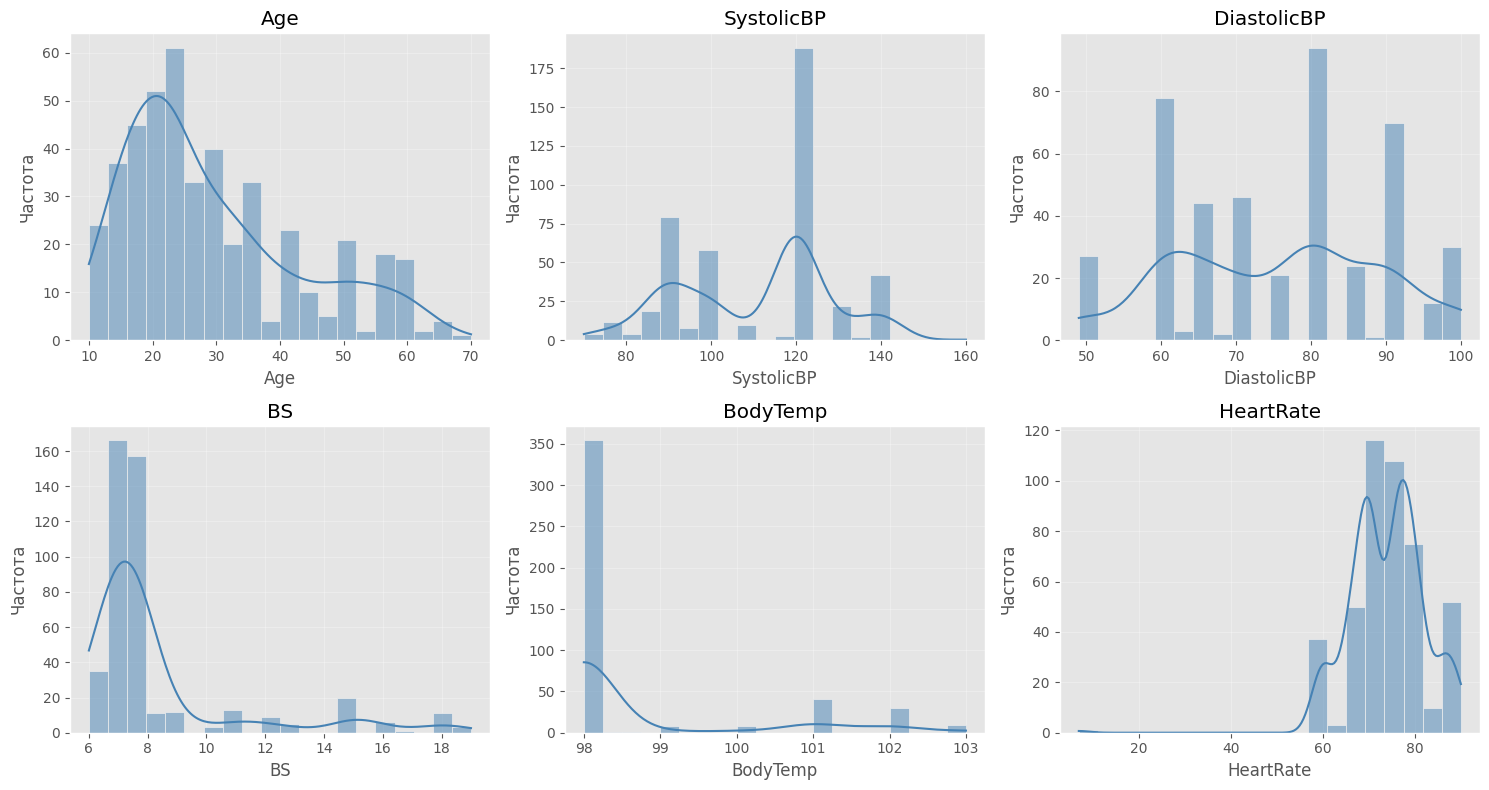

/tmp/ipykernel_103239/1723146363.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=column, order=['low risk', 'mid risk', 'high risk'],ax=ax, palette='Set2')


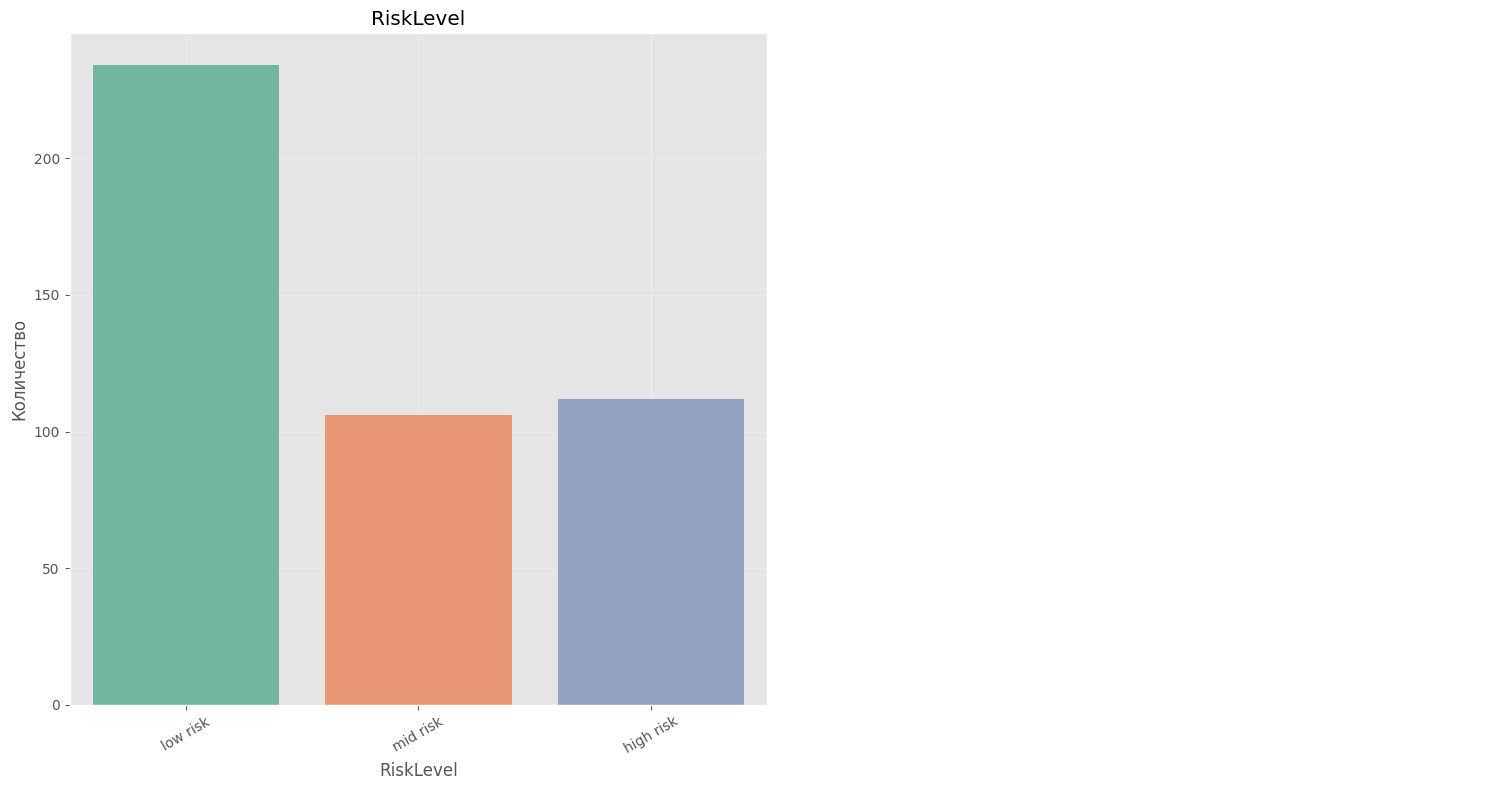

In [147]:
plot_fig(['Age', 'SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate'], 3, 2)
plot_fig(['RiskLevel'], 2, 1, False)

### Выводы по графикам распределения

- **Наиболее информативные признаки:** `BS`, `SystolicBP`, `DiastolicBP` —
  их распределения мультимодальны или имеют длинные хвосты, соответствующие
  различным клиническим группам.
- **`HeartRate`** — умеренно информативен: распределение близко к нормальному,
  с заметной асимметрией, что может помогать в разделении
  классов. Также присутствует выраженный выброс в области малых значений —
  его стоит удалить на этапе предобработки.
- **Слабый признак:** `BodyTemp` — почти все значения равны 98 °F, поэтому
  его вклад в модель будет минимальным.
- **`Age`** полезен, но требует осторожности: распределение скошено,
  данных по старшим возрастам мало — прогноз для них менее надёжен.

###Дополнительно построим boxplot для каждого числового признака с разбивкой по трём уровням риска.

/tmp/ipykernel_103239/1908824009.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='RiskLevel', y=col, ax=ax, order=['low risk', 'mid risk', 'high risk'], palette='Set2')
/tmp/ipykernel_103239/1908824009.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='RiskLevel', y=col, ax=ax, order=['low risk', 'mid risk', 'high risk'], palette='Set2')
/tmp/ipykernel_103239/1908824009.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='RiskLevel', y=col, ax=ax, order=['low risk', 'mid risk', 'high risk'], palette='Se

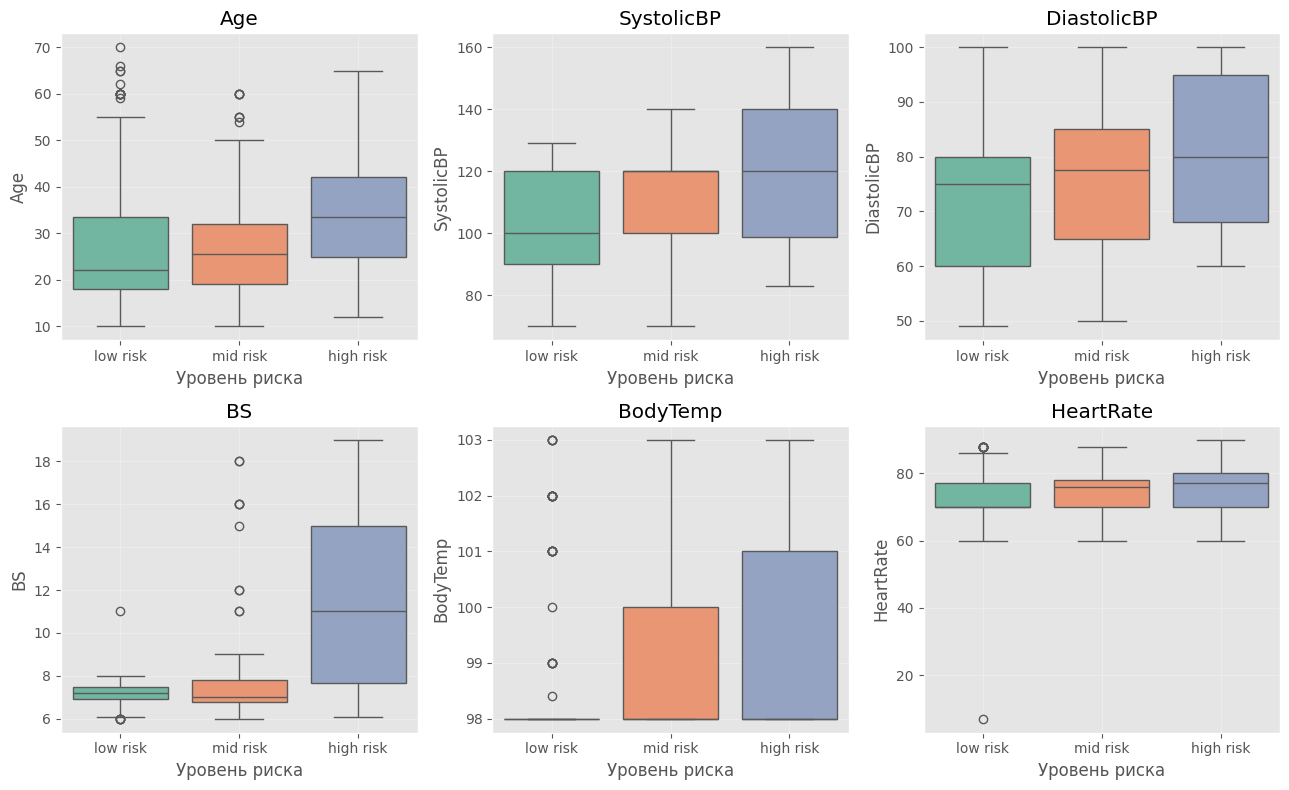

In [148]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, col in zip(axes.ravel(), ['Age', 'SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate']):
    sns.boxplot(data=df, x='RiskLevel', y=col, ax=ax, order=['low risk', 'mid risk', 'high risk'], palette='Set2')
    ax.set_title(col)
    ax.set_xlabel('Уровень риска')
    ax.set_ylabel(col)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Интересные выводы по графикам

- **`SystolicBP` и `DiastolicBP`** — сильные признаки для выделения `high risk`:
  у этого класса медианы заметно выше, чем у `low` и `mid`. Однако эти признаки
  почти не различают `low` и `mid risk` — их ящики сильно пересекаются.

- **`BS`** — самый информативный признак: медианы чётко
  растут от `low` к `mid` и к `high`, а ящики
  почти не пересекаются. Именно `BS` лучше всего разделяет все три класса.

- **`BodyTemp`** — слабый, но ненулевой признак: у `low risk` значения
  практически всегда равны 98 °F, тогда как при `mid` и `high risk`
  встречаются повышенные значения. Это делает температуру
  полезным вспомогательным индикатором, но не основным предиктором.

- **`HeartRate`** — сам по себе классы не разделяет,
  но у `high risk` медиана чуть выше. Обнаружен явный выброс у `low risk`, который, вероятно, является ошибкой ввода и подлежит удалению на этапе предобработки.

**Ключевое наблюдение:** `low` и `mid risk` плохо разделяются большинством
признаков (кроме `BS`) — модель, скорее всего, будет путать именно эти
два класса.

### Построение корреляционной матрицы Пирсона

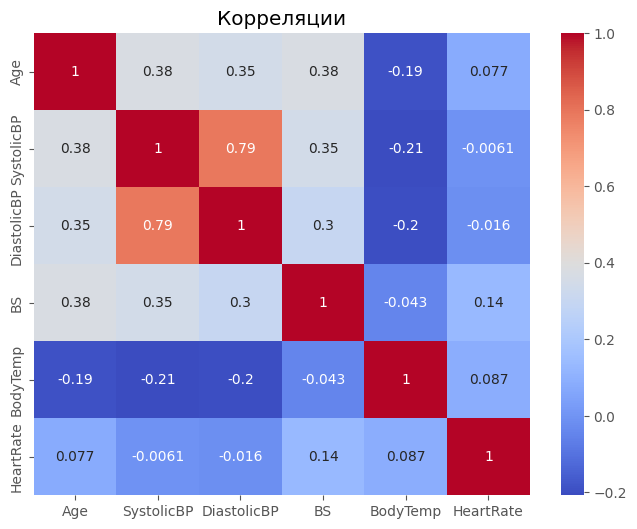

In [149]:
plt.figure(figsize=(8,6))
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, cmap='coolwarm')
plt.title('Корреляции')
plt.show()

### Переход к этапу предобработки данных

На этом этапе EDA завершён: мы построили графики распределений, сделали выводы
по данным, удалили дубликаты в датасете, определили подходящие метрики и наметили, как обрабатывать выбросы.
Теперь переходим к предобработке данных для машинного обучения.

Начнём предобработку с удаления наблюдения с некорректным значением
признака `HeartRate`, которое было обнаружено при анализе графиков
распределения.

In [150]:
print(df['HeartRate'].unique())

df = df[df['HeartRate'] != 7].reset_index(drop=True)
print(df['HeartRate'].unique())

[86 70 80 76 78 77 88 90 66 82 60 75 67 65 68  7]
[86 70 80 76 78 77 88 90 66 82 60 75 67 65 68]


После очистки данных от некорректных значений можно перейти к кодированию
категориальной целевой переменной и разбиению выборки на тренировочную
и тестовую. Разбиение выполним **со стратификацией**, поскольку классы
несбалансированы — это позволит сохранить их пропорции в обеих частях.

In [151]:
mapping = {'low risk': 0, 'mid risk': 1, 'high risk': 2}
df['RiskLevel'] = df['RiskLevel'].map(mapping)
print(df.head())

X = df.drop(columns=['RiskLevel'])
y = df['RiskLevel']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

   Age  SystolicBP  DiastolicBP    BS  BodyTemp  HeartRate  RiskLevel
0   25         130           80  15.0      98.0         86          2
1   35         140           90  13.0      98.0         70          2
2   29          90           70   8.0     100.0         80          2
3   30         140           85   7.0      98.0         70          2
4   35         120           60   6.1      98.0         76          0


## Переход к построению моделей

Перейдём к самому интересному этапу — построению и обучению моделей машинного обучения.

Для решения задачи многоклассовой классификации с умеренным дисбалансом классов мы обучим **четыре базовые модели: Logistic Regression, SVM, KNN и Decision Tree**; **ансамбль деревьев Random Forest, градиентный бустинг CatBoost**, и в конце объединим все модели в **мета-ансабль Stacking**:
### Перед обучением определим ключевые компоненты пайплайна:

- **Метрика качества `scorer`** — будем использовать `f1_macro`, которая устойчива к дисбалансу классов и одинаково учитывает качество по всем трём классам риска.
- **Схема кросс-валидации `cv`** — стратифицированная 5-фолдовая кросс-валидация (`StratifiedKFold`), сохраняющая пропорции классов в каждом фолде.
- **Объекты для тюнинга** — для каждой модели определим свой `objective`-функционал для Optuna.

In [152]:
scorer = make_scorer(f1_score, average='macro')
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [153]:
def objective_logreg(trial):
    params = {
        'C': trial.suggest_float('C', 1e-3, 1e2, log=True),
        'solver': 'lbfgs',
        'max_iter': 1000,
        'class_weight': 'balanced',
        'random_state': 42,
    }
    model = Pipeline([
        ('sc', StandardScaler()),
        ('clf', LogisticRegression(**params))
    ])
    return cross_val_score(model, X_train, y_train, cv=cv, scoring=scorer, n_jobs=-1).mean()

def objective_svm(trial):
    params = {
        'C': trial.suggest_float('C', 1e-3, 1e2, log=True),
        'gamma': trial.suggest_float('gamma', 1e-4, 1e1, log=True),
        'kernel': trial.suggest_categorical('kernel', ['rbf', 'linear']),
        'class_weight': 'balanced',
        'random_state': 42,
    }
    model = Pipeline([
        ('sc', StandardScaler()),
        ('svc', SVC(**params))
    ])
    return cross_val_score(model, X_train, y_train, cv=cv, scoring=scorer, n_jobs=-1).mean()


def objective_knn(trial):
    params = {
        'n_neighbors': trial.suggest_int('n_neighbors', 3, 15),
        'weights': trial.suggest_categorical('weights', ['uniform', 'distance']),
        'p': trial.suggest_int('p', 1, 2),
    }
    model = Pipeline([
        ('sc', StandardScaler()),
        ('knn', KNeighborsClassifier(**params))
    ])
    return cross_val_score(model, X_train, y_train, cv=cv, scoring=scorer, n_jobs=-1).mean()


def objective_tree(trial):
    params = {
        'max_depth': trial.suggest_int('max_depth', 3, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'criterion': trial.suggest_categorical('criterion', ['gini', 'entropy']),
        'class_weight': 'balanced',
        'random_state': 42,
    }
    model = DecisionTreeClassifier(**params)
    return cross_val_score(model, X_train, y_train, cv=cv, scoring=scorer, n_jobs=-1).mean()


def objective_rf(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 800, step=100),
        'max_depth': trial.suggest_int('max_depth', 3, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', None]),
        'class_weight': 'balanced',
        'random_state': 42,
        'n_jobs': -1,
    }
    model = RandomForestClassifier(**params)
    return cross_val_score(model, X_train, y_train, cv=cv, scoring=scorer, n_jobs=-1).mean()


def objective_cat(trial):
    params = {
        'iterations': trial.suggest_int('iterations', 100, 700, step=100),
        'depth': trial.suggest_int('depth', 3, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1, 10),
        'auto_class_weights': 'Balanced',
        'loss_function': 'MultiClass',
        'random_seed': 42,
        'verbose': 0,
    }
    model = CatBoostClassifier(**params)
    return cross_val_score(model, X_train, y_train, cv=cv, scoring=scorer, n_jobs=-1).mean()


objectives = {
    'LogReg': objective_logreg,
    'SVM': objective_svm,
    'KNN': objective_knn,
    'DecisionTree': objective_tree,
    'RandomForest': objective_rf,
    'CatBoost': objective_cat,
}

### Запускаем подбор гиперпараметров для каждой модели.

In [154]:
studies = {}
for name, obj in objectives.items():
    print(f'\nМодель {name}:')
    study = optuna.create_study(
        direction='maximize',
        sampler=TPESampler(seed=42)
    )
    study.optimize(obj, n_trials=100, show_progress_bar=True)
    studies[name] = study
    print(f'Лучший CV f1_macro: {study.best_value:.4f}')
    print(f'Лучшие параметры: {study.best_params}')


Модель LogReg:


  0%|          | 0/100 [00:00<?, ?it/s]

Лучший CV f1_macro: 0.5812
Лучшие параметры: {'C': 0.0040842616875572}

Модель SVM:


  0%|          | 0/100 [00:00<?, ?it/s]

Лучший CV f1_macro: 0.6369
Лучшие параметры: {'C': 2.3594692110349436, 'gamma': 0.08806721195070741, 'kernel': 'rbf'}

Модель KNN:


  0%|          | 0/100 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Лучший CV f1_macro: 0.6817
Лучшие параметры: {'n_estimators': 400, 'max_depth': 5, 'min_samples_split': 5, 'min_samples_leaf': 6, 'max_features': 'log2'}

Модель CatBoost:


  0%|          | 0/100 [00:00<?, ?it/s]

Лучший CV f1_macro: 0.6846
Лучшие параметры: {'iterations': 100, 'depth': 3, 'learning_rate': 0.018387078502886407, 'l2_leaf_reg': 5.336849120514303}


После подбора гиперпараметров через Optuna полезно **заглянуть внутрь процесса оптимизации** — это помогает понять, насколько хорошо сработал тюнинг и какие гиперпараметры действительно влияют на качество модели.

/tmp/ipykernel_103239/3786070787.py:1: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(studies['SVM'])


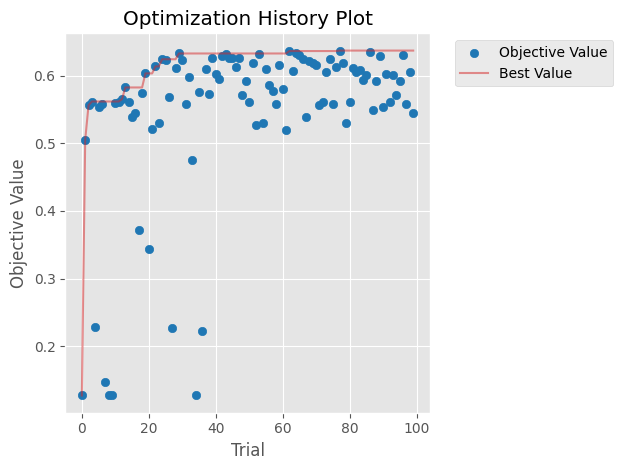

/tmp/ipykernel_103239/3786070787.py:5: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_param_importances(studies['SVM'])


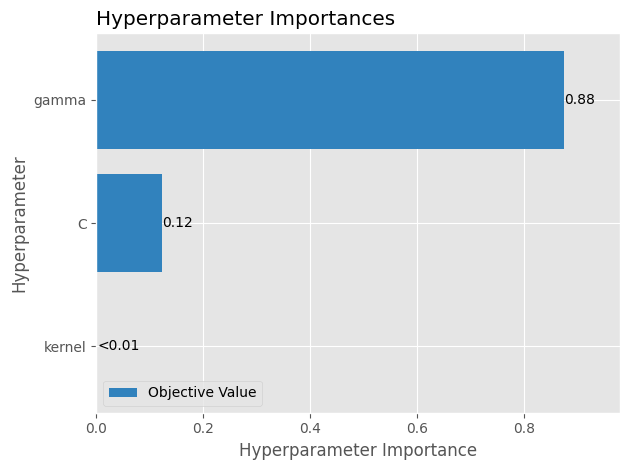

In [174]:
plot_optimization_history(studies['SVM'])
plt.tight_layout()
plt.show()

ax = plot_param_importances(studies['SVM'])
plt.tight_layout()
plt.show()

## Обучение финальных моделей и оценка метрик

После того как Optuna подобрала оптимальные гиперпараметры для каждой модели, мы переходим к следующему этапу — обучению финальных моделей на полной тренировочной выборке.

In [156]:
def build_model(name, params):
    if name == 'LogReg':
        return Pipeline([
            ('sc', StandardScaler()),
            ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42, **params))
        ])
    if name == 'SVM':
        return Pipeline([
            ('sc', StandardScaler()),
            ('svc', SVC(class_weight='balanced', random_state=42, **params))
        ])
    if name == 'KNN':
        return Pipeline([
            ('sc', StandardScaler()),
            ('knn', KNeighborsClassifier(**params))
        ])
    if name == 'DecisionTree':
        return DecisionTreeClassifier(class_weight='balanced', random_state=42, **params)
    if name == 'RandomForest':
        return RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1, **params)
    if name == 'CatBoost':
        return CatBoostClassifier(auto_class_weights='Balanced', loss_function='MultiClass', random_seed=42, verbose=0, **params)

In [157]:
results = {}
best_models = {}

for name, study in studies.items():
    model = build_model(name, study.best_params)
    model.fit(X_train, y_train)
    best_models[name] = model

    y_pred_tr = model.predict(X_train)
    y_pred_te = model.predict(X_test)

    results[name] = {
        'cv_f1_macro': study.best_value,
        'f1_macro_train': f1_score(y_train, y_pred_tr, average='macro'),
        'f1_macro_test': f1_score(y_test,  y_pred_te, average='macro'),
        'bal_acc_test': balanced_accuracy_score(y_train, y_pred_tr),
        'bal_acc_test': balanced_accuracy_score(y_test, y_pred_te),
        'cm_train': confusion_matrix(y_train, y_pred_tr),
        'cm_test': confusion_matrix(y_test,  y_pred_te),
        'best_params': study.best_params,
    }

Отдельно обучим **стекинг** — мета-ансамбль, который объединяет предсказания нескольких базовых моделей с помощью финального оценщика.

In [158]:
# Переопределим формирование пайплайна для модели SVM для обучения стекинга
def build_base_for_stacking(name, params):
    if name == 'SVM':
        p = {k: v for k, v in params.items()}  # копия
        return Pipeline([
            ('sc', StandardScaler()),
            ('svc', SVC(class_weight='balanced', probability=True, random_state=42, **p))
        ])
    return build_model(name, params)


stacking_estimators = [
    (name.lower(), build_base_for_stacking(name, studies[name].best_params))
    for name in ['LogReg', 'SVM', 'RandomForest', 'CatBoost'] # Удалили из списка моделей DecisionTree и KNN как слабые модели
]

stacking = StackingClassifier(
    estimators=stacking_estimators,
    final_estimator=LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    cv=cv,
    n_jobs=-1,
    passthrough=False
)

stacking.fit(X_train, y_train)

y_pred_tr = stacking.predict(X_train)
y_pred_te = stacking.predict(X_test)

results['Stacking'] = {
    'cv_f1_macro': np.nan,  # стекинг уже использует CV внутри
    'f1_macro_train': f1_score(y_train, y_pred_tr, average='macro'),
    'f1_macro_test': f1_score(y_test,  y_pred_te, average='macro'),
    'bal_acc_test': balanced_accuracy_score(y_train, y_pred_tr),
    'bal_acc_test': balanced_accuracy_score(y_test, y_pred_te),
    'cm_train': confusion_matrix(y_train, y_pred_tr),
    'cm_test': confusion_matrix(y_test,  y_pred_te),
    'best_params': '—',
}
best_models['Stacking'] = stacking

### Вывод и сравнение метрик всех обученных моделей

После того как все модели обучены и их метрики сохранены в словаре `results`, соберём итоговую таблицу и отсортируем модели по **целевой метрике `f1_macro_test`**.

In [159]:
res_df = pd.DataFrame({name: {k: v for k, v in vals.items() if k not in ('cm_train', 'cm_test', 'best_params')} for name, vals in results.items()}).T

res_df = res_df.sort_values('f1_macro_test', ascending=False)
print(res_df.round(4))

              cv_f1_macro  f1_macro_train  f1_macro_test  bal_acc_test
Stacking              NaN          0.7058         0.6413        0.6398
SVM                0.6369          0.6979         0.6383        0.6398
RandomForest       0.6817          0.7321         0.6358        0.6512
CatBoost           0.6846          0.6937         0.6301        0.6310
LogReg             0.5812          0.6049         0.6276        0.6210
KNN                0.6079          0.6787         0.5838        0.5919
DecisionTree       0.6388          0.6653         0.5788        0.5774


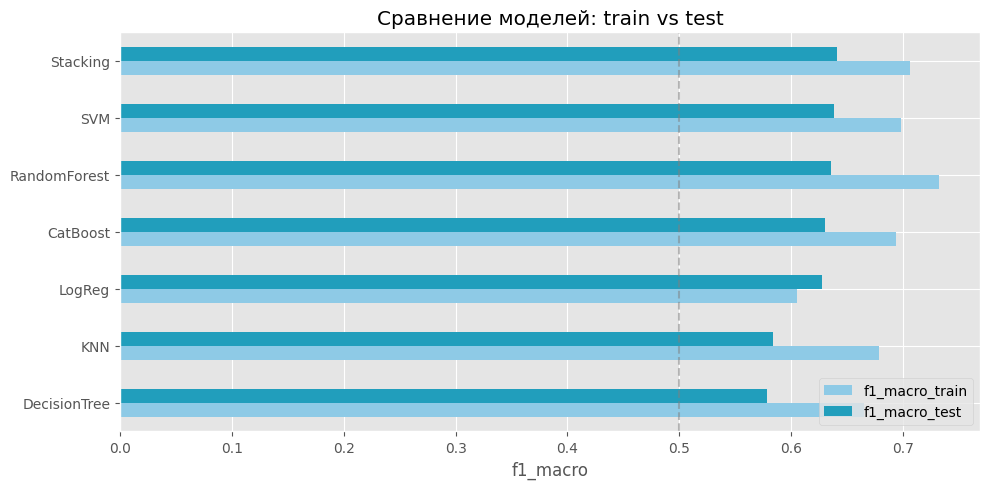

In [160]:
fig, ax = plt.subplots(figsize=(10, 5))
res_plot = res_df[['f1_macro_train', 'f1_macro_test']].sort_values('f1_macro_test')
res_plot.plot(kind='barh', ax=ax, color=['#8ecae6', '#219ebc'])
ax.set_xlabel('f1_macro')
ax.set_title('Сравнение моделей: train vs test')
ax.axvline(0.5, color='gray', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Матрицы ошибок для всех моделей

Построим матрицы ошибок (`confusion_matrix`) для каждой модели — отдельно на train и test. Они показывают, **какие классы модели путают**, что скрыто за усреднёнными метриками вроде `f1_macro`.

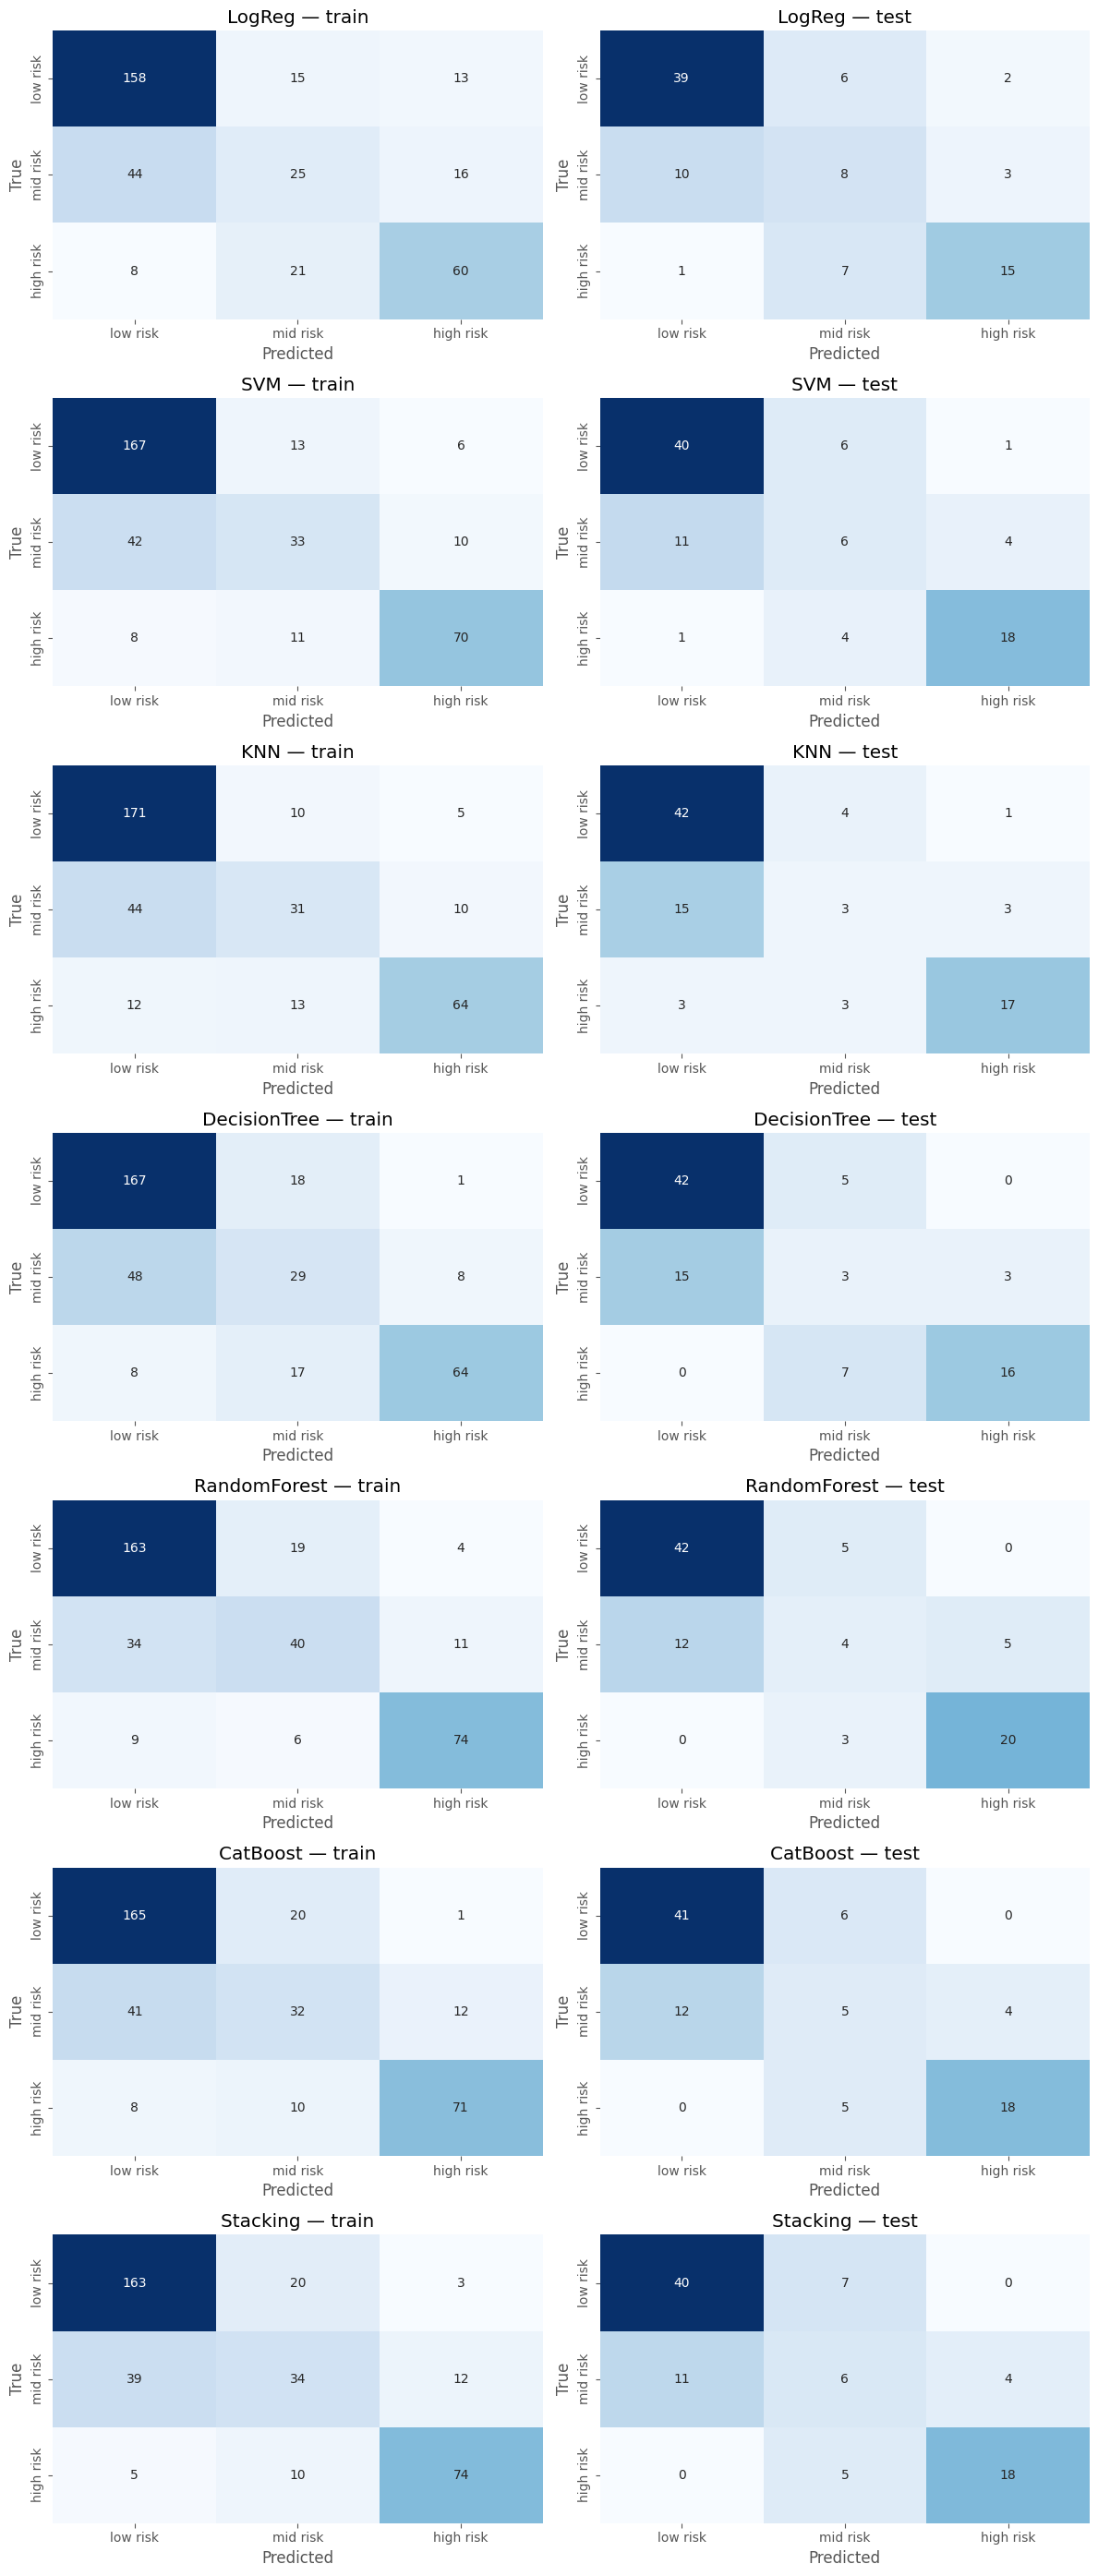

In [161]:
n_models = len(results)
fig, axes = plt.subplots(n_models, 2, figsize=(12, 4 * n_models))
axes = np.atleast_2d(axes)

for i, (name, vals) in enumerate(results.items()):
    for j, (split, cm) in enumerate([('train', vals['cm_train']), ('test',  vals['cm_test'])]):
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i, j], xticklabels=mapping.keys(), yticklabels=mapping.keys(), cbar=False)
        axes[i, j].set_title(f'{name} — {split}')
        axes[i, j].set_xlabel('Predicted')
        axes[i, j].set_ylabel('True')

plt.tight_layout()
plt.show()

In [162]:
best_name = res_df['f1_macro_test'].idxmax()
best_model = best_models[best_name]

print(f'Лучшая модель по f1_macro_test: {best_name}')
print(f'Параметры: {results[best_name]["best_params"]}\n')

print('--- TRAIN ---')
print(classification_report(y_train, best_model.predict(X_train),
                            target_names=mapping.keys()))
print('\n--- TEST ---')
print(classification_report(y_test, best_model.predict(X_test),
                            target_names=mapping.keys()))

Лучшая модель по f1_macro_test: Stacking
Параметры: —

--- TRAIN ---
              precision    recall  f1-score   support

    low risk       0.79      0.88      0.83       186
    mid risk       0.53      0.40      0.46        85
   high risk       0.83      0.83      0.83        89

    accuracy                           0.75       360
   macro avg       0.72      0.70      0.71       360
weighted avg       0.74      0.75      0.74       360


--- TEST ---
              precision    recall  f1-score   support

    low risk       0.78      0.85      0.82        47
    mid risk       0.33      0.29      0.31        21
   high risk       0.82      0.78      0.80        23

    accuracy                           0.70        91
   macro avg       0.65      0.64      0.64        91
weighted avg       0.69      0.70      0.69        91

